In [12]:
# trader_3.py — diagnosis (trial_3 / 171553)
# Loads: strategy file, challenge rules summary, memory notes, trial JSON/log.
import json
import io
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/Users/devansharora/Desktop/Trading_System/IMC_Prosperity")
TRIAL_JSON = ROOT / "Round_1/ROUND1/logs2/169826.json"
TRADER_PY = ROOT / "Round_1/ROUND1/trader_3.py"
CHALLENGE = ROOT / "Challenge_Info/challenge_info.txt"
MEMORY = ROOT / "Round_1/ROUND1/memory.md"

with open(TRIAL_JSON) as f:
    trial = json.load(f)

print("=== Trial run ===")
print("status:", trial.get("status"), "profit:", trial.get("profit"))
print("round:", trial.get("round"))

activities_raw = trial["activitiesLog"]
df = pd.read_csv(io.StringIO(activities_raw), sep=";")
print("activity rows:", len(df), "products:", df["product"].unique().tolist())


=== Trial run ===
status: FINISHED profit: 8511.59375
round: 1
activity rows: 2000 products: ['ASH_COATED_OSMIUM', 'INTARIAN_PEPPER_ROOT']


<Axes: >

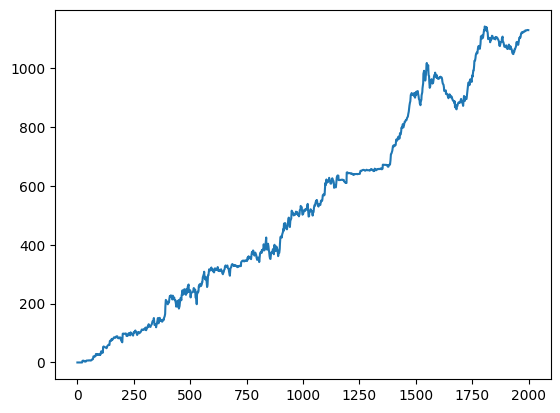

In [20]:
os = df[df['product']=='ASH_COATED_OSMIUM']
os['profit_and_loss'].plot()

<Axes: >

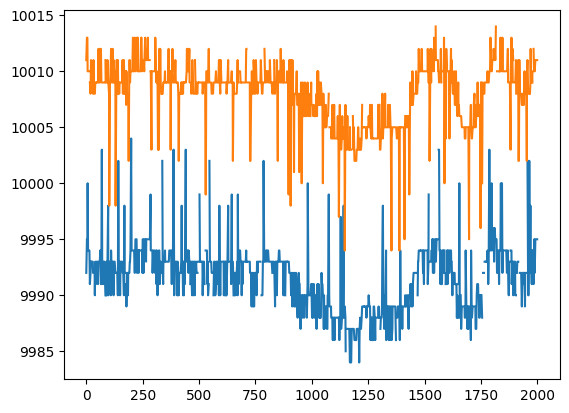

In [22]:
os['bid_price_1'].plot()
os['ask_price_1'].plot()

In [11]:
# PnL by product (from activities log — cumulative profit_and_loss at last row per product)
last_pnl = (
    df.sort_values(["day", "timestamp"])
    .groupby("product", as_index=False)
    .last()[["product", "profit_and_loss"]]
)
print("=== Ending cumulative PnL (mark-to-market column in log) ===")
print(last_pnl.to_string(index=False))
pepper_end = float(last_pnl.loc[last_pnl["product"] == "INTARIAN_PEPPER_ROOT", "profit_and_loss"].iloc[0])
osmium_end = float(last_pnl.loc[last_pnl["product"] == "ASH_COATED_OSMIUM", "profit_and_loss"].iloc[0])
print("\nInterpretation: Pepper still makes most money (buy-and-hold drift), Osmium adds a smaller slice.")
print("Total trial profit from JSON:", trial.get("profit"))


=== Ending cumulative PnL (mark-to-market column in log) ===
             product  profit_and_loss
   ASH_COATED_OSMIUM       1128.59375
INTARIAN_PEPPER_ROOT       7383.00000

Interpretation: Pepper still makes most money (buy-and-hold drift), Osmium adds a smaller slice.
Total trial profit from JSON: 8511.59375


In [3]:
# CRITICAL: fitted "fair" lines vs actual mid drift (INTARIAN_PEPPER_ROOT)
# Strategy uses: ask_eq = 12006 + 0.05*t, bid_eq = 11991 + 0.05*t  with t = state.timestamp

pep = df[df["product"] == "INTARIAN_PEPPER_ROOT"].sort_values(["day", "timestamp"]).copy()
pep = pep.dropna(subset=["mid_price"])
pep["center_eq"] = (12006 + 11991) / 2 + 0.05 * pep["timestamp"]
pep["residual_mid_minus_eq"] = pep["mid_price"] - pep["center_eq"]

slope_ols, intercept_ols = np.polyfit(pep["timestamp"], pep["mid_price"], 1)

print("=== Pepper: strategy model vs market ===")
print("Strategy PEPPER_SLOPE = 0.05  =>  implied mid line drifts +0.05 per timestamp unit.")
print(f"OLS on actual mid_price vs timestamp: slope = {slope_ols:.6f}, intercept ≈ {intercept_ols:.2f}")
print(f"Ratio: model_slope / actual_ols_slope ≈ {0.05 / slope_ols:.1f}x  (model is far steeper than reality)\n")

show = pep[["timestamp", "mid_price", "center_eq", "residual_mid_minus_eq"]]
print("First 3 rows:")
print(show.head(3).to_string(index=False))
print("\nLast 3 rows (same day):")
print(show.tail(3).to_string(index=False))
print(f"\nResidual stats: mean={pep['residual_mid_minus_eq'].mean():.1f}  std={pep['residual_mid_minus_eq'].std():.1f}")
print("At late timestamps, bid_eq and ask_eq are THOUSANDS above the real book → Phase-2 inequalities are meaningless.")

print("\n=== Why Phase 2 breaks ===")
print("Code checks:  best_ask < ask_eq  and  best_bid > bid_eq  (when spread < 7).")
print("When ask_eq ≈ 17000 but best_ask ≈ 12100,  'best_ask < ask_eq' is TRUE always (vacuous).")
print("When bid_eq ≈ 16980 but best_bid ≈ 12090, 'best_bid > bid_eq' is FALSE always.")
print("So the 'spike' sell branch never fires; the 'cheap ask' buy branch is mis-triggered whenever spread is tight.")


=== Pepper: strategy model vs market ===
Strategy PEPPER_SLOPE = 0.05  =>  implied mid line drifts +0.05 per timestamp unit.
OLS on actual mid_price vs timestamp: slope = 0.001272, intercept ≈ 11974.32
Ratio: model_slope / actual_ols_slope ≈ 39.3x  (model is far steeper than reality)

First 3 rows:
 timestamp  mid_price  center_eq  residual_mid_minus_eq
         0    11998.5    11998.5                    0.0
       100    12002.0    12003.5                   -1.5
       200    11999.0    12008.5                   -9.5

Last 3 rows (same day):
 timestamp  mid_price  center_eq  residual_mid_minus_eq
     99700    12099.5    16983.5                -4884.0
     99800    12099.5    16988.5                -4889.0
     99900    12099.5    16993.5                -4894.0

Residual stats: mean=-2458.1  std=1457.9
At late timestamps, bid_eq and ask_eq are THOUSANDS above the real book → Phase-2 inequalities are meaningless.

=== Why Phase 2 breaks ===
Code checks:  best_ask < ask_eq  and  best_bi

In [4]:
# How often is spread < 7? (Phase 2 gate)
pep2 = df[df["product"] == "INTARIAN_PEPPER_ROOT"].copy()
has = pep2.dropna(subset=["ask_price_1", "bid_price_1"], how="any").copy()
has["book_spread"] = has["ask_price_1"] - has["bid_price_1"]
frac_tight = (has["book_spread"] < 7).mean()
print("=== Phase 2 frequency ===")
print(f"Rows with both bid_price_1 and ask_price_1: {len(has)}")
print(f"Fraction with (ask - bid) < 7: {frac_tight:.2%}")
print("Phase 2 is rare; most ticks are Phase-1 lift-the-offer only.")


=== Phase 2 frequency ===
Rows with both bid_price_1 and ask_price_1: 910
Fraction with (ask - bid) < 7: 2.97%
Phase 2 is rare; most ticks are Phase-1 lift-the-offer only.


In [5]:
# Logic gap: Phase 1 + Phase 2 same tick (memory says "once full" for vol trading — code does not gate)
print("=== Code vs memory.md ===")
print("memory.md: 'Phase 1 accumulate; Phase 2 when position is full' (conceptual).")
print("trader_3.py: Phase 2 runs whenever spread < 7, even while position < 80.")
print("Together with Phase 1 always buying at best ask, you can buy and add Phase-2 buys in one tick,")
print("or churn inventory — inconsistent with a clean two-stage design.\n")

text = TRADER_PY.read_text().splitlines()
for i, line in enumerate(text[59:99], start=60):
    print(f"{i:4d}  {line}")


=== Code vs memory.md ===
memory.md: 'Phase 1 accumulate; Phase 2 when position is full' (conceptual).
trader_3.py: Phase 2 runs whenever spread < 7, even while position < 80.
Together with Phase 1 always buying at best ask, you can buy and add Phase-2 buys in one tick,
or churn inventory — inconsistent with a clean two-stage design.

  60      def _trade_pepper(self, state: TradingState, trader_state: dict) -> list[Order]:
  61          orders: list[Order] = []
  62          position = state.position.get(PEPPER, 0)
  63          order_depth: OrderDepth = state.order_depths[PEPPER]
  64          t = state.timestamp
  65  
  66          ask_eq = PEPPER_ASK_INTERCEPT + PEPPER_SLOPE * t
  67          bid_eq = PEPPER_BID_INTERCEPT + PEPPER_SLOPE * t
  68  
  69          best_ask = min(order_depth.sell_orders.keys()) if order_depth.sell_orders else None
  70          best_bid = max(order_depth.buy_orders.keys()) if order_depth.buy_orders else None
  71  
  72          max_buy = POSITION_LIM

In [6]:
# Challenge exchange rules (from challenge_info.txt) — what matters for debugging
from pathlib import Path
CHALLENGE = Path("/Users/devansharora/Desktop/Trading_System/IMC_Prosperity/Challenge_Info/challenge_info.txt")
print("=== challenge_info.txt — Order quantity ===")
print('Order quantity: positive = BUY, negative = SELL (trader_3 uses +vol buys and -sell_vol sells — consistent).')
print()
print("=== Position limits ===")
print("If aggregated buy or sell quantities in ONE iteration would exceed the per-product limit, ALL orders cancelled.")
print("trader_3 caps with max_buy/max_sell and uses abs(book size) — generally consistent.")
print()
print("=== Order book convention (OrderDepth) ===")
print("sell_orders values are negative volumes; buy_orders positive — trader_3 uses abs() — consistent.")


=== challenge_info.txt — Order quantity ===
Order quantity: positive = BUY, negative = SELL (trader_3 uses +vol buys and -sell_vol sells — consistent).

=== Position limits ===
If aggregated buy or sell quantities in ONE iteration would exceed the per-product limit, ALL orders cancelled.
trader_3 caps with max_buy/max_sell and uses abs(book size) — generally consistent.

=== Order book convention (OrderDepth) ===
sell_orders values are negative volumes; buy_orders positive — trader_3 uses abs() — consistent.


In [7]:
# ASH_COATED_OSMIUM: hard anchor 10_000 vs old trader (memory: EMA + Z-score)
print("=== Osmium (trader_3) ===")
print("Strategy: sweep asks <= 10000, hit bids >= 10000, then post 9999 bid / 10001 ask for remainder.")
print("Risk: if mid wanders but does not cross 10k, you still lean on a fixed anchor; old trader blended EMA + anchor.")
print("Trial ending Osmium PnL (from activities):", osmium_end)
print("This is not 'wrong' per se — but it is a different thesis than trader.py (momentum + Z reversal).")


=== Osmium (trader_3) ===
Strategy: sweep asks <= 10000, hit bids >= 10000, then post 9999 bid / 10001 ask for remainder.
Risk: if mid wanders but does not cross 10k, you still lean on a fixed anchor; old trader blended EMA + anchor.
Trial ending Osmium PnL (from activities): 882.8125
This is not 'wrong' per se — but it is a different thesis than trader.py (momentum + Z reversal).


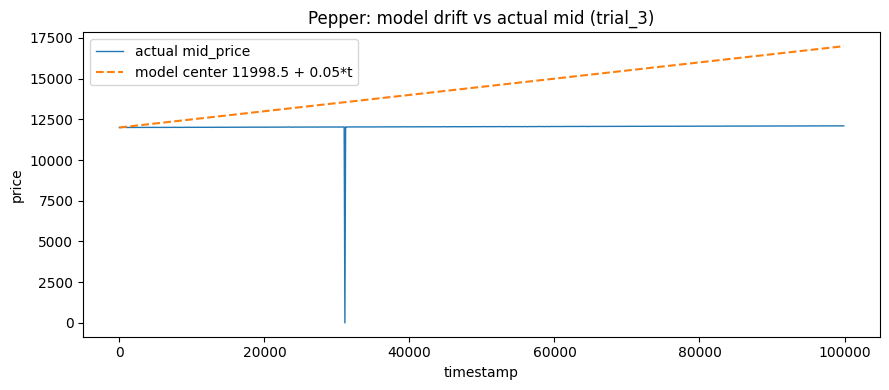

In [8]:
# Plot: model drift vs actual mid (optional — install matplotlib if missing)
pep = df[df["product"] == "INTARIAN_PEPPER_ROOT"].sort_values(["day", "timestamp"]).dropna(subset=["mid_price"])
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(pep["timestamp"], pep["mid_price"], label="actual mid_price", linewidth=1)
    ax.plot(pep["timestamp"], (12006 + 11991) / 2 + 0.05 * pep["timestamp"], label="model center 11998.5 + 0.05*t", linestyle="--")
    ax.set_xlabel("timestamp")
    ax.set_ylabel("price")
    ax.legend()
    ax.set_title("Pepper: model drift vs actual mid (trial_3)")
    plt.tight_layout()
    plt.show()
except ModuleNotFoundError:
    print("matplotlib not installed; skipping figure. (pip install matplotlib)")


In [9]:
# Summary — root causes (executable checklist)
print("""
1) MIS-CALIBRATED DRIFT (main issue)
   bid_eq/ask_eq use slope 0.05 * timestamp. On this run, mid drifts ~""" + f"{slope_ols:.6f}" + """ * t, not 0.05*t.
   After many iterations the model price is thousands away from the real book, so Phase-2 tests do not detect spikes.

2) PHASE 2 DESIGN MISMATCH
   memory.md describes vol trading after filling; code does not require position==80.

3) PHASE 2 RARE + ONE-SIDED WHEN MODEL IS WRONG
   Spread < 7 is ~3% of rows here; combined with (1), ask_eq >> market makes best_ask < ask_eq vacuously true when tight.

4) OSMIUM
   Different thesis vs trader.py; smaller contribution — not an API bug.

5) NOT A DATAMODEL BUG
   Order signs and abs() on book sizes match challenge_info.
""")



1) MIS-CALIBRATED DRIFT (main issue)
   bid_eq/ask_eq use slope 0.05 * timestamp. On this run, mid drifts ~0.001272 * t, not 0.05*t.
   After many iterations the model price is thousands away from the real book, so Phase-2 tests do not detect spikes.

2) PHASE 2 DESIGN MISMATCH
   memory.md describes vol trading after filling; code does not require position==80.

3) PHASE 2 RARE + ONE-SIDED WHEN MODEL IS WRONG
   Spread < 7 is ~3% of rows here; combined with (1), ask_eq >> market makes best_ask < ask_eq vacuously true when tight.

4) OSMIUM
   Different thesis vs trader.py; smaller contribution — not an API bug.

5) NOT A DATAMODEL BUG
   Order signs and abs() on book sizes match challenge_info.

